# Oficina de Exploração do Saeb 2023 — Pernambuco (9º Ano EF)
### Proficiência em Matemática e Língua Portuguesa × Conectividade × Nível Socioeconômico (INSE)

- **Recorte:** Microdados do **Saeb 2023** (`TS_ALUNO_9EF.csv`) · **9º ano do Ensino Fundamental** (`ID_SERIE = 9`) · **Pernambuco** (`ID_UF = 26`, Região Nordeste) · `1 linha = 1 estudante`.
- **Ponte com o Censo Escolar 2023:** na oficina anterior (*Escada Tecnológica*), analisamos a infraestrutura digital declarada pela escola. O Saeb 2023 preenche três lacunas centrais: **conectividade na casa do estudante**, **nível socioeconômico individual (`INSE_ALUNO` / `NU_TIPO_NIVEL_INSE`)** e **proficiência medida em Matemática e Língua Portuguesa**.
- **Compatibilidade entre dicionários (Saeb 2023 × Censo 2023):**
  - **Batem:** `ID_SAEB`=`NU_ANO_CENSO` (`2023`), `ID_REGIAO`=`CO_REGIAO`, `ID_UF`=`CO_UF` (`26`), `ID_LOCALIZACAO`=`TP_LOCALIZACAO` (`1`=Urbana, `2`=Rural); `IN_PUBLICA` bate com `TP_DEPENDENCIA` recodificada (`{1,2,3}→1`, `{4}→0`).
  - **Não batem (LGPD):** `ID_ESCOLA` e `ID_MUNICIPIO` no Saeb são **máscaras fictícias iniciadas por `6`** (0 sobreposição com `CO_ENTIDADE`/`CO_MUNICIPIO` do Censo), mas batem 100% internamente entre as tabelas do próprio Saeb.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

UF_CODIGO, UF_SIGLA, UF_NOME = 26, "PE", "Pernambuco"
BASE_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "oficina_saeb_2023" else os.path.abspath(".")
PATH_SAEB_9EF = os.path.join(BASE_DIR, "MICRODADOS_SAEB_2023", "DADOS", "TS_ALUNO_9EF.csv")
DIR_SAIDAS = os.path.join(BASE_DIR, "oficina_saeb_2023", "saidas")
os.makedirs(DIR_SAIDAS, exist_ok=True)

COLS = [
    "ID_SAEB", "ID_UF", "ID_MUNICIPIO", "ID_ESCOLA", "IN_PUBLICA", "ID_LOCALIZACAO",
    "ID_ALUNO", "IN_SITUACAO_CENSO", "IN_PREENCHIMENTO_QUESTIONARIO",
    "PESO_ALUNO_MT", "PESO_ALUNO_LP",
    "IN_INSE", "INSE_ALUNO", "NU_TIPO_NIVEL_INSE", "PESO_ALUNO_INSE",
    "TX_RESP_Q13b", "TX_RESP_Q12b", "TX_RESP_Q12g",
    "PROFICIENCIA_MT_SAEB", "PROFICIENCIA_LP_SAEB"
]

df = pd.concat(
    [c[c["ID_UF"] == UF_CODIGO] for c in pd.read_csv(PATH_SAEB_9EF, sep=";", encoding="latin1", usecols=COLS, chunksize=250_000, low_memory=False)],
    ignore_index=True
)

mask_inse_valido = (df["IN_INSE"] == 1) & df["INSE_ALUNO"].notna()

ficha = pd.DataFrame([
    ("Edição / Etapa / Território", "Saeb 2023 · 9º ano EF · Pernambuco (ID_UF = 26)"),
    ("Total de registros (1 linha = 1 estudante)", f"{len(df):,}"),
    ("Escolas / Municípios distintos (mascarados)", f"{df['ID_ESCOLA'].nunique():,} escolas · {df['ID_MUNICIPIO'].nunique():,} municípios"),
    ("Rede (IN_PUBLICA)", f"Pública: {(df['IN_PUBLICA']==1).sum():,} | Privada (amostral): {(df['IN_PUBLICA']==0).sum():,}"),
    ("Localização (ID_LOCALIZACAO)", f"Urbana: {(df['ID_LOCALIZACAO']==1).sum():,} | Rural: {(df['ID_LOCALIZACAO']==2).sum():,}"),
    ("Consistentes com Censo 2023", f"{(df['IN_SITUACAO_CENSO']==1).sum():,} ({(df['IN_SITUACAO_CENSO']==1).mean()*100:.1f}%)"),
    ("Proficiência válida (MT / LP)", f"{df['PROFICIENCIA_MT_SAEB'].notna().sum():,} ({df['PROFICIENCIA_MT_SAEB'].notna().mean()*100:.1f}%)"),
    ("INSE válido (IN_INSE=1 e INSE_ALUNO não nulo)", f"{mask_inse_valido.sum():,} ({mask_inse_valido.mean()*100:.1f}%)"),
    ("Questionário preenchido / Peso MT válido", f"{(df['IN_PREENCHIMENTO_QUESTIONARIO']==1).sum():,} / {(df['PESO_ALUNO_MT'].fillna(0)>0).sum():,}"),
], columns=["Item", "Recorte Pernambuco (PE)"])

display(ficha)

,Item,Recorte Pernambuco (PE)
0,Edição / Etapa / Território,Saeb 2023 · 9º ano EF · Pernambuco (ID_UF = 26)
1,Total de registros (1 linha = 1 estudante),"109,542"
2,Escolas / Municípios distintos (mascarados),"1,450 escolas · 185 municípios"
3,Rede (IN_PUBLICA),"Pública: 107,556 | Privada (amostral): 1,986"
4,Localização (ID_LOCALIZACAO),"Urbana: 91,505 | Rural: 18,037"
5,Consistentes com Censo 2023,"108,470 (99.0%)"
6,Proficiência válida (MT / LP),"96,313 (87.9%)"
7,INSE válido (IN_INSE=1 e INSE_ALUNO não nulo),"91,011 (83.1%)"
8,Questionário preenchido / Peso MT válido,"96,150 / 95,947"


---
## Variáveis Selecionadas (`TS_ALUNO_9EF.csv`)

| Coluna escolhida | O que registra | Valores válidos e cuidados metodológicos (Dicionário Saeb 2023) |
|---|---|---|
| `TX_RESP_Q13b` | Na sua casa tem: Rede Wi-Fi | **Válidos:** `A`=Não; `B`=Sim · **Especiais:** `.`=Branco; `*`=Nulo; `NaN` |
| `TX_RESP_Q12b` | Quantos existem na casa: Computador/notebook | **Válidos:** `A`=Nenhum; `B`=1; `C`=2; `D`=3 ou mais · **Especiais:** `.`, `*`, `NaN` |
| `TX_RESP_Q12g` | Quantos existem na casa: Smartphone c/ internet | **Válidos:** `A`=Nenhum; `B`=1; `C`=2; `D`=3 ou mais · **Especiais:** `.`, `*`, `NaN` |
| `INSE_ALUNO` | Indicador de Nível Socioeconômico individual | **Válidos:** numérico contínuo (2,12 a 7,62 em PE) · **Especial:** `NaN` quando `IN_INSE = 0` |
| `NU_TIPO_NIVEL_INSE` | Classificação do INSE em 8 grupos (Nível 1 a 8) | **Atenção crítica:** no CSV bruto, ausentes (`INSE_ALUNO = NaN`) aparecem codificados como `1`. **Sempre filtrar `IN_INSE == 1` e `INSE_ALUNO.notna()`** antes de agrupar! |
| `PROFICIENCIA_MT_SAEB` | Proficiência em Matemática (escala Saeb) | **Válidos:** numérico contínuo (média 250, DP 50) · **Especial:** `NaN` |
| `PROFICIENCIA_LP_SAEB` | Proficiência em Língua Portuguesa (escala Saeb) | **Válidos:** numérico contínuo (média 250, DP 50) · **Especial:** `NaN` |

In [2]:
# 4.1 Tabela consolidada das 3 variáveis categóricas (denominador = respostas válidas; ausências separadas)
LEGENDAS = {
    "TX_RESP_Q13b": ("Rede Wi-Fi em casa", {"A": "Não", "B": "Sim"}),
    "TX_RESP_Q12b": ("Computador/notebook em casa", {"A": "Nenhum", "B": "1", "C": "2", "D": "3 ou mais"}),
    "TX_RESP_Q12g": ("Smartphone c/ internet em casa", {"A": "Nenhum", "B": "1", "C": "2", "D": "3 ou mais"}),
}

rows_cat = []
for col, (desc, mapa) in LEGENDAS.items():
    s = df[col]
    n_val = int(s.isin(mapa.keys()).sum())
    for k, rotulo in mapa.items():
        qtd = int((s == k).sum())
        rows_cat.append({
            "Variável": col, "Descrição": desc, "Tipo": "Válido", "Categoria": f"{k} - {rotulo}",
            "Quantidade": qtd, "% sobre válidos": round(qtd / n_val * 100, 1), "Denominador válido": n_val
        })
    for k, rotulo in [(".", "Branco"), ("*", "Nulo")]:
        qtd = int((s == k).sum())
        rows_cat.append({
            "Variável": col, "Descrição": desc, "Tipo": "Especial/Ausência", "Categoria": f"{k} - {rotulo}",
            "Quantidade": qtd, "% sobre válidos": np.nan, "Denominador válido": n_val
        })

df_cat = pd.DataFrame(rows_cat)
print("=== Frequências das 3 variáveis de conectividade (PE, Saeb 2023) ===")
display(df_cat)

# 4.2 Resumo numérico das 2 proficiências + INSE_ALUNO
def resumo_num(col, peso, nome, filtro=None):
    base = df if filtro is None else df[filtro]
    v = base[col].dropna()
    mp = base[col].notna() & (base[peso].fillna(0) > 0)
    return {
        "Indicador": nome, "Coluna": col,
        "N válidos": int(len(v)), "Ausentes (NaN)": int(len(df) - len(v)),
        "% Ausentes": round((len(df) - len(v)) / len(df) * 100, 1),
        "Média simples": round(v.mean(), 2), "Mín": round(v.min(), 2), "Máx": round(v.max(), 2),
        "Média ponderada (peso)": round(np.average(base.loc[mp, col], weights=base.loc[mp, peso]), 2),
    }

df_prof = pd.DataFrame([
    resumo_num("PROFICIENCIA_MT_SAEB", "PESO_ALUNO_MT", "Matemática"),
    resumo_num("PROFICIENCIA_LP_SAEB", "PESO_ALUNO_LP", "Língua Portuguesa"),
    resumo_num("INSE_ALUNO", "PESO_ALUNO_INSE", "INSE do Aluno (IN_INSE=1)", filtro=mask_inse_valido),
])
print("\n=== Resumo numérico: Proficiências e INSE_ALUNO (PE, Saeb 2023) ===")
display(df_prof)

=== Frequências das 3 variáveis de conectividade (PE, Saeb 2023) ===


,Variável,Descrição,Tipo,Categoria,Quantidade,% sobre válidos,Denominador válido
0,TX_RESP_Q13b,Rede Wi-Fi em casa,Válido,A - Não,8172,9.0,90322
1,TX_RESP_Q13b,Rede Wi-Fi em casa,Válido,B - Sim,82150,91.0,90322
2,TX_RESP_Q13b,Rede Wi-Fi em casa,Especial/Ausência,. - Branco,18642,NaN,90322
3,TX_RESP_Q13b,Rede Wi-Fi em casa,Especial/Ausência,* - Nulo,578,NaN,90322
4,TX_RESP_Q12b,Computador/notebook em casa,Válido,A - Nenhum,58696,67.4,87081
5,TX_RESP_Q12b,Computador/notebook em casa,Válido,B - 1,19482,22.4,87081
6,TX_RESP_Q12b,Computador/notebook em casa,Válido,C - 2,6208,7.1,87081
7,TX_RESP_Q12b,Computador/notebook em casa,Válido,D - 3 ou mais,2695,3.1,87081
8,TX_RESP_Q12b,Computador/notebook em casa,Especial/Ausência,. - Branco,19256,NaN,87081
9,TX_RESP_Q12b,Computador/notebook em casa,Especial/Ausência,* - Nulo,3205,NaN,87081



=== Resumo numérico: Proficiências e INSE_ALUNO (PE, Saeb 2023) ===


,Indicador,Coluna,N válidos,Ausentes (NaN),% Ausentes,Média simples,Mín,Máx,Média ponderada (peso)
0,Matemática,PROFICIENCIA_MT_SAEB,96313,13229,12.1,248.59,108.84,419.96,255.14
1,Língua Portuguesa,PROFICIENCIA_LP_SAEB,96313,13229,12.1,250.98,125.11,379.45,257.50
2,INSE do Aluno (IN_INSE=1),INSE_ALUNO,91011,18531,16.9,4.52,2.12,7.62,4.73


,WiFi,N_validos,Media_MT,Media_LP
0,Sem Wi-Fi,8147,239.18,239.1
1,Com Wi-Fi,81922,250.38,253.0


,Computador,N_validos,Media_MT,Media_LP
0,Nenhum,58541,246.03,248.07
1,1,19421,258.79,262.56
2,2,6186,257.13,260.22
3,3 ou mais,2682,257.72,256.49



=== Correlação de Spearman com Proficiência (PE, Saeb 2023) ===


,Matemática,Língua Portuguesa
INSE_ALUNO (contínuo),0.138,0.149
NU_TIPO_NIVEL_INSE (1-8),0.136,0.146
Computador (Q12b),0.111,0.123
Smartphone (Q12g),0.102,0.112
Wi-Fi (Q13b),0.064,0.081


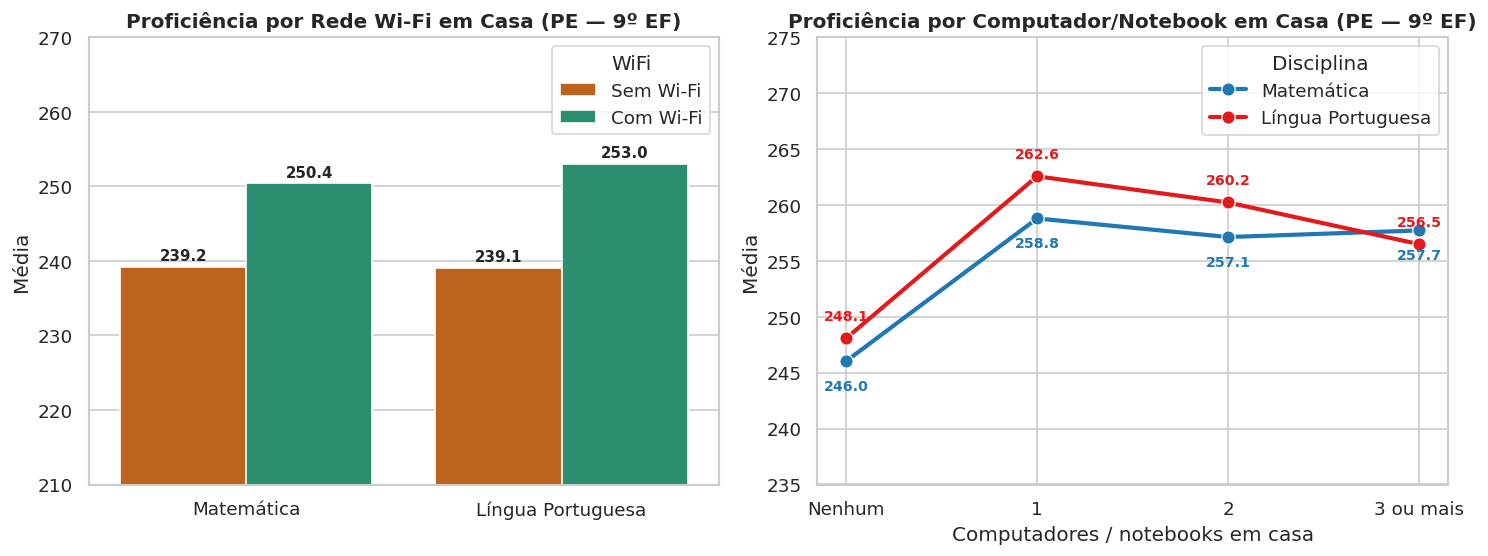

In [3]:
# Comparação 1: Com Wi-Fi vs. Sem Wi-Fi (TX_RESP_Q13b)
df_wifi = df[df["TX_RESP_Q13b"].isin(["A", "B"])].copy()
df_wifi["WiFi"] = df_wifi["TX_RESP_Q13b"].map({"A": "Sem Wi-Fi", "B": "Com Wi-Fi"})
comp_wifi = (
    df_wifi.groupby("WiFi")
    .agg(N_validos=("PROFICIENCIA_MT_SAEB", lambda s: s.notna().sum()),
         Media_MT=("PROFICIENCIA_MT_SAEB", "mean"),
         Media_LP=("PROFICIENCIA_LP_SAEB", "mean"))
    .round(2).reindex(["Sem Wi-Fi", "Com Wi-Fi"]).reset_index()
)

# Comparação 2: Computador/notebook em casa (TX_RESP_Q12b)
df_pc = df[df["TX_RESP_Q12b"].isin(["A", "B", "C", "D"])].copy()
df_pc["Computador"] = df_pc["TX_RESP_Q12b"].map({"A": "Nenhum", "B": "1", "C": "2", "D": "3 ou mais"})
comp_pc = (
    df_pc.groupby("Computador")
    .agg(N_validos=("PROFICIENCIA_MT_SAEB", lambda s: s.notna().sum()),
         Media_MT=("PROFICIENCIA_MT_SAEB", "mean"),
         Media_LP=("PROFICIENCIA_LP_SAEB", "mean"))
    .round(2).reindex(["Nenhum", "1", "2", "3 ou mais"]).reset_index()
)

# Correlação de Spearman (exploratória, sem peso) incluindo INSE_ALUNO e NU_TIPO_NIVEL_INSE limpo
inse_nivel_limpo = df["NU_TIPO_NIVEL_INSE"].where(mask_inse_valido, np.nan)
df_corr = pd.DataFrame({
    "INSE_ALUNO (contínuo)": df["INSE_ALUNO"].where(mask_inse_valido, np.nan),
    "NU_TIPO_NIVEL_INSE (1-8)": inse_nivel_limpo,
    "Computador (Q12b)": df["TX_RESP_Q12b"].map({"A": 0, "B": 1, "C": 2, "D": 3}),
    "Smartphone (Q12g)": df["TX_RESP_Q12g"].map({"A": 0, "B": 1, "C": 2, "D": 3}),
    "Wi-Fi (Q13b)": df["TX_RESP_Q13b"].map({"A": 0, "B": 1}),
    "Matemática": df["PROFICIENCIA_MT_SAEB"],
    "Língua Portuguesa": df["PROFICIENCIA_LP_SAEB"],
}).corr(method="spearman").loc[
    ["INSE_ALUNO (contínuo)", "NU_TIPO_NIVEL_INSE (1-8)", "Computador (Q12b)", "Smartphone (Q12g)", "Wi-Fi (Q13b)"],
    ["Matemática", "Língua Portuguesa"]
].round(3)

display(comp_wifi)
display(comp_pc)
print("\n=== Correlação de Spearman com Proficiência (PE, Saeb 2023) ===")
display(df_corr)

# Gráfico 1: Conectividade (Wi-Fi e Computador) x Proficiência
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), dpi=120)

w_melt = comp_wifi.melt("WiFi", ["Media_MT", "Media_LP"], "Disciplina", "Média")
w_melt["Disciplina"] = w_melt["Disciplina"].map({"Media_MT": "Matemática", "Media_LP": "Língua Portuguesa"})
sns.barplot(data=w_melt, x="Disciplina", y="Média", hue="WiFi", palette=["#d95f02", "#1b9e77"], ax=axes[0])
axes[0].set_title("Proficiência por Rede Wi-Fi em Casa (PE — 9º EF)", fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylim(210, 270)
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.1f", fontsize=9, fontweight="bold", padding=2)

p_melt = comp_pc.melt("Computador", ["Media_MT", "Media_LP"], "Disciplina", "Média")
p_melt["Disciplina"] = p_melt["Disciplina"].map({"Media_MT": "Matemática", "Media_LP": "Língua Portuguesa"})
sns.lineplot(data=p_melt, x="Computador", y="Média", hue="Disciplina", marker="o", linewidth=2.5, markersize=8,
             palette=["#1f78b4", "#e31a1c"], ax=axes[1])
axes[1].set_title("Proficiência por Computador/Notebook em Casa (PE — 9º EF)", fontweight="bold")
axes[1].set_xlabel("Computadores / notebooks em casa")
axes[1].set_ylim(235, 275)
for _, r in comp_pc.iterrows():
    axes[1].text(r["Computador"], r["Media_MT"] - 2.6, f"{r['Media_MT']:.1f}", ha="center", fontsize=8.5, color="#1f78b4", fontweight="bold")
    axes[1].text(r["Computador"], r["Media_LP"] + 1.6, f"{r['Media_LP']:.1f}", ha="center", fontsize=8.5, color="#e31a1c", fontweight="bold")

plt.tight_layout()
fig_path = os.path.join(DIR_SAIDAS, "evidencia_saeb_PE_2023.png")
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()

=== Proficiência e Conectividade por Nível do INSE (PE — filtro limpo IN_INSE=1) ===


,NU_TIPO_NIVEL_INSE,N_alunos,INSE_medio,Media_MT,Media_LP,Pct_WiFi,Pct_Computador
0,1,2046,2.72,234.00,231.74,16.76,2.33
1,2,19467,3.64,242.13,242.98,79.45,6.82
2,3,23787,4.26,246.12,249.39,94.08,16.92
3,4,22542,4.73,250.27,253.95,96.74,35.44
4,5,13628,5.22,255.81,258.71,98.13,58.98
5,6,6194,5.71,260.65,263.15,98.97,80.92
6,7,2794,6.32,269.54,267.36,99.42,95.00
7,8,295,7.26,281.66,272.09,99.66,100.00



=== Proficiência por Nível do INSE × Posse de Computador (PE, Saeb 2023) ===


Possui_PC,Com PC,Sem PC,Dif_MT (Com - Sem PC)
NU_TIPO_NIVEL_INSE,,,
1,222.98,235.68,-12.70
2,242.16,242.85,-0.69
3,250.84,245.96,4.88
4,255.27,248.66,6.61
5,259.88,252.38,7.50
6,263.61,251.97,11.64
7,271.31,255.91,15.40
8,282.79,NaN,NaN


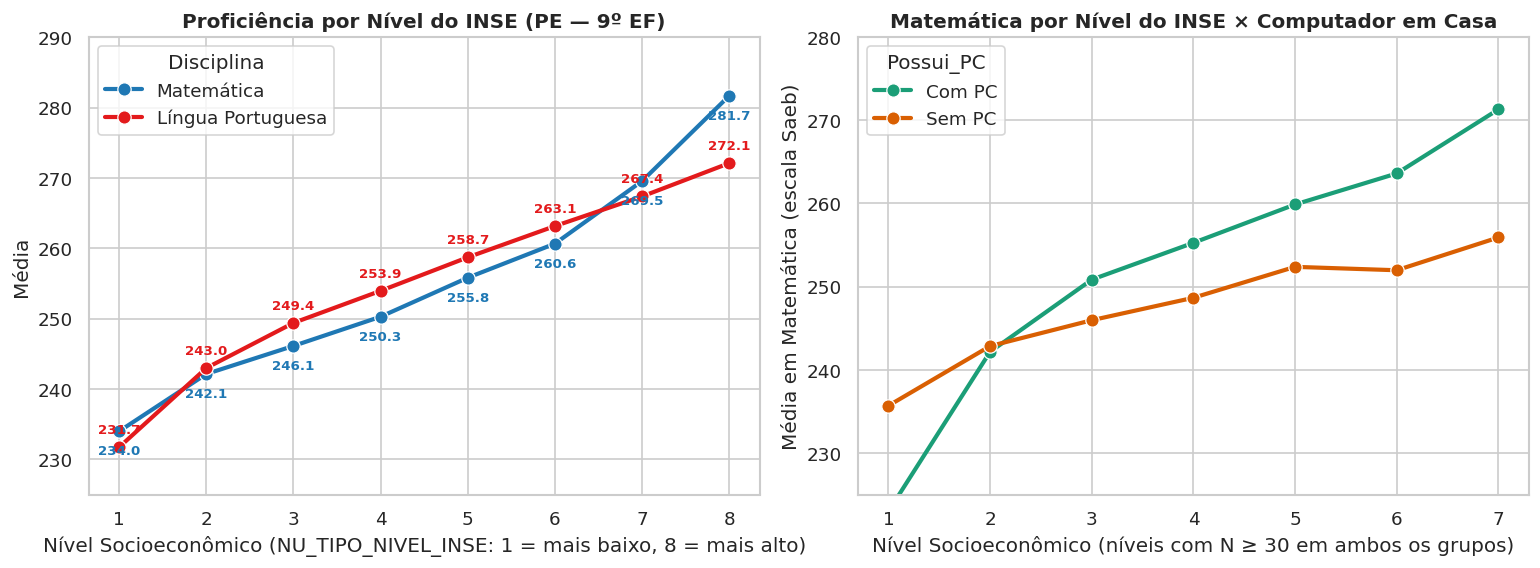

In [4]:
# Base limpa de INSE: obrigatoriamente IN_INSE == 1 e INSE_ALUNO não nulo (evita contaminação do Nível 1)
df_inse = df[mask_inse_valido & df["PROFICIENCIA_MT_SAEB"].notna() & df["PROFICIENCIA_LP_SAEB"].notna()].copy()
df_inse["Tem_WiFi"] = df_inse["TX_RESP_Q13b"].map({"A": 0, "B": 1})
df_inse["Tem_PC"] = df_inse["TX_RESP_Q12b"].map({"A": 0, "B": 1, "C": 1, "D": 1})

# 6.1 Tabela agregada por NU_TIPO_NIVEL_INSE (Níveis 1 a 8)
resumo_inse = (
    df_inse.groupby("NU_TIPO_NIVEL_INSE")
    .agg(
        N_alunos=("ID_ALUNO", "count"),
        INSE_medio=("INSE_ALUNO", "mean"),
        Media_MT=("PROFICIENCIA_MT_SAEB", "mean"),
        Media_LP=("PROFICIENCIA_LP_SAEB", "mean"),
        Pct_WiFi=("Tem_WiFi", lambda s: s.mean() * 100),
        Pct_Computador=("Tem_PC", lambda s: s.mean() * 100),
    )
    .round(2)
    .reset_index()
)
resumo_inse["NU_TIPO_NIVEL_INSE"] = resumo_inse["NU_TIPO_NIVEL_INSE"].astype(int)

print("=== Proficiência e Conectividade por Nível do INSE (PE — filtro limpo IN_INSE=1) ===")
display(resumo_inse)

# 6.2 Cruzamento: efeito de Computador e Wi-Fi DENTRO de cada Nível do INSE
df_inse_pc = df_inse[df_inse["Tem_PC"].notna()].copy()
df_inse_pc["Possui_PC"] = df_inse_pc["Tem_PC"].map({0.0: "Sem PC", 1.0: "Com PC"})
cruz_inse_pc = (
    df_inse_pc.groupby(["NU_TIPO_NIVEL_INSE", "Possui_PC"])
    .agg(N=("ID_ALUNO", "count"), Media_MT=("PROFICIENCIA_MT_SAEB", "mean"), Media_LP=("PROFICIENCIA_LP_SAEB", "mean"))
    .round(2)
    .reset_index()
)
cruz_inse_pc["NU_TIPO_NIVEL_INSE"] = cruz_inse_pc["NU_TIPO_NIVEL_INSE"].astype(int)

print("\n=== Proficiência por Nível do INSE × Posse de Computador (PE, Saeb 2023) ===")
pivot_pc_mt = cruz_inse_pc.pivot(index="NU_TIPO_NIVEL_INSE", columns="Possui_PC", values="Media_MT")
pivot_pc_mt["Dif_MT (Com - Sem PC)"] = (pivot_pc_mt["Com PC"] - pivot_pc_mt["Sem PC"]).round(2)
display(pivot_pc_mt)

# Gráfico 2: Gradiente do INSE (MT vs LP) + Cruzamento INSE × Computador (Matemática)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.9), dpi=120)

# Painel A: MT e LP por Nível do INSE
inse_melt = resumo_inse.melt("NU_TIPO_NIVEL_INSE", ["Media_MT", "Media_LP"], "Disciplina", "Média")
inse_melt["Disciplina"] = inse_melt["Disciplina"].map({"Media_MT": "Matemática", "Media_LP": "Língua Portuguesa"})
sns.lineplot(data=inse_melt, x="NU_TIPO_NIVEL_INSE", y="Média", hue="Disciplina",
             marker="o", linewidth=2.5, markersize=8, palette=["#1f78b4", "#e31a1c"], ax=axes[0])
axes[0].set_title("Proficiência por Nível do INSE (PE — 9º EF)", fontweight="bold")
axes[0].set_xlabel("Nível Socioeconômico (NU_TIPO_NIVEL_INSE: 1 = mais baixo, 8 = mais alto)")
axes[0].set_xticks(range(1, 9))
axes[0].set_ylim(225, 290)
for _, r in resumo_inse.iterrows():
    axes[0].text(r["NU_TIPO_NIVEL_INSE"], r["Media_MT"] - 3.3, f"{r['Media_MT']:.1f}", ha="center", fontsize=8, color="#1f78b4", fontweight="bold")
    axes[0].text(r["NU_TIPO_NIVEL_INSE"], r["Media_LP"] + 2.0, f"{r['Media_LP']:.1f}", ha="center", fontsize=8, color="#e31a1c", fontweight="bold")

# Painel B: Matemática por Nível do INSE separado por Com PC vs. Sem PC (níveis com N >= 30 em ambos)
valid_lvls = cruz_inse_pc.pivot(index="NU_TIPO_NIVEL_INSE", columns="Possui_PC", values="N")
lvls_plot = valid_lvls[(valid_lvls["Sem PC"] >= 30) & (valid_lvls["Com PC"] >= 30)].index
sns.lineplot(data=cruz_inse_pc[cruz_inse_pc["NU_TIPO_NIVEL_INSE"].isin(lvls_plot)],
             x="NU_TIPO_NIVEL_INSE", y="Media_MT", hue="Possui_PC",
             marker="o", linewidth=2.5, markersize=8, palette=["#1b9e77", "#d95f02"], ax=axes[1])
axes[1].set_title("Matemática por Nível do INSE × Computador em Casa", fontweight="bold")
axes[1].set_xlabel("Nível Socioeconômico (níveis com N ≥ 30 em ambos os grupos)")
axes[1].set_ylabel("Média em Matemática (escala Saeb)")
axes[1].set_xticks(list(lvls_plot))
axes[1].set_ylim(225, 280)

plt.tight_layout()
fig_inse_path = os.path.join(DIR_SAIDAS, "evidencia_inse_conectividade_PE_2023.png")
plt.savefig(fig_inse_path, dpi=150, bbox_inches="tight")
plt.show()

---
## Achado, Dúvida, Limite e Perguntas para Continuar

- **Achado (Conectividade + INSE):** Em Pernambuco (Saeb 2023, 9º ano EF, `N = 109.542` estudantes em `1.450` escolas):
  1. **Conectividade:** **91,0%** têm Wi-Fi e **97,8%** têm smartphone, mas **67,4%** não possuem computador/notebook. Quem tem Wi-Fi pontua mais em **Matemática** (`250,38` vs. `239,18`; **+11,20 pts**) e **Língua Portuguesa** (`253,00` vs. `239,10`; **+13,90 pts**).
  2. **Fator Socioeconômico (`INSE_ALUNO` e `NU_TIPO_NIVEL_INSE`):** o INSE apresenta correlação de Spearman mais forte que qualquer variável isolada de conectividade (`MT: 0,139`; `LP: 0,149`). Do **Nível 1** ao **Nível 8** do INSE, a média salta **+47,66 pontos em Matemática** (`234,00 → 281,66`) e **+40,35 pontos em Língua Portuguesa** (`231,74 → 272,09`), enquanto a posse de computador sobe de ~0% no Nível 1 para >95% nos níveis mais altos.
  3. **Auditoria de qualidade:** no CSV bruto, os `18.531` estudantes com `INSE_ALUNO = NaN` vêm marcados como `NU_TIPO_NIVEL_INSE = 1`. O filtro `IN_INSE == 1` e `INSE_ALUNO.notna()` foi aplicado para evitar distorção no Nível 1.
- **Dúvida:** Controlando simultaneamente por `INSE_ALUNO`, `ID_LOCALIZACAO` (Urbana/Rural) e `IN_PUBLICA`, e aplicando os pesos amostrais (`PESO_ALUNO_MT`/`LP`), quanto da diferença de nota atribuída ao computador/Wi-Fi permanece estatisticamente relevante?
- **Limite:** (1) Associação observacional **não implica causalidade**; (2) médias simples descrevem o recorte — inferências populacionais exigem pesos (`PESO_ALUNO_MT`/`LP`/`INSE`); (3) `ID_ESCOLA` e `ID_MUNICIPIO` são mascarados por LGPD (`6...`), impedindo cruzamento direto por escola com o Censo Escolar 2023.

### Duas Perguntas para Continuar (Base: `TS_ALUNO_9EF.csv`, PE, Saeb 2023)
1. ⭐ **[PRIORIDADE] Contexto de Matemática:** *Qual é o efeito associado ao acesso à internet/computador em casa (`TX_RESP_Q13b`, `TX_RESP_Q12b`, `TX_RESP_Q12g`) sobre a proficiência em **Matemática** (`PROFICIENCIA_MT_SAEB`) em Pernambuco, controlando por `INSE_ALUNO` e usando `PESO_ALUNO_MT`?*
2. **Contexto de Língua Portuguesa:** *O mesmo padrão se mantém em **Língua Portuguesa** (`PROFICIENCIA_LP_SAEB`) com `PESO_ALUNO_LP`, ou a conectividade tem peso distinto entre leitura e matemática dentro do mesmo nível socioeconômico?*

In [5]:
df_vars = pd.DataFrame([
    ("TX_RESP_Q13b", "Na sua casa tem: Rede Wi-Fi", "A=Não; B=Sim | Especiais: .=Branco, *=Nulo, NaN"),
    ("TX_RESP_Q12b", "Quantos existem na casa: Computador/notebook", "A=Nenhum; B=1; C=2; D=3 ou mais | Especiais: ., *, NaN"),
    ("TX_RESP_Q12g", "Quantos existem na casa: Smartphone c/ internet", "A=Nenhum; B=1; C=2; D=3 ou mais | Especiais: ., *, NaN"),
    ("INSE_ALUNO", "Indicador de Nível Socioeconômico individual", "Numérico contínuo (válido quando IN_INSE=1) | Especial: NaN"),
    ("NU_TIPO_NIVEL_INSE", "Classificação do INSE em 8 grupos (1 a 8)", "1 a 8 (filtrar IN_INSE=1 e INSE_ALUNO não nulo)"),
    ("PROFICIENCIA_MT_SAEB", "Proficiência em Matemática (escala Saeb)", "Numérico contínuo (média 250, DP 50) | Especial: NaN"),
    ("PROFICIENCIA_LP_SAEB", "Proficiência em Língua Portuguesa (escala Saeb)", "Numérico contínuo (média 250, DP 50) | Especial: NaN"),
], columns=["Coluna escolhida", "O que registra", "Valores válidos e códigos especiais"])

excel_path = os.path.join(DIR_SAIDAS, "planilha_analise_saeb_2023_PE.xlsx")
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    ficha.to_excel(writer, sheet_name="Ficha_Recorte_PE", index=False)
    df_vars.to_excel(writer, sheet_name="Variaveis_Selecionadas", index=False)
    df_cat.to_excel(writer, sheet_name="Frequencias_Categoricas", index=False)
    df_prof.to_excel(writer, sheet_name="Resumo_Numerico_INSE", index=False)
    comp_wifi.to_excel(writer, sheet_name="Comparacao_WiFi", index=False)
    comp_pc.to_excel(writer, sheet_name="Comparacao_Computador", index=False)
    resumo_inse.to_excel(writer, sheet_name="Resumo_INSE_Niveis", index=False)
    cruz_inse_pc.to_excel(writer, sheet_name="INSE_x_Computador", index=False)
    df_corr.reset_index().to_excel(writer, sheet_name="Correlacoes_Spearman", index=False)

print("Planilha atualizada com abas do INSE:", excel_path)

Planilha atualizada com abas do INSE: /home/jorge/Documentos/Faculdade/Materias-Faculdade/mineracao-educacional/oficina_saeb_2023/saidas/planilha_analise_saeb_2023_PE.xlsx
